### Partie 1 : Exploer et verifier des donner 

#### 1 .

In [151]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
df = pd.read_csv('transactions_TP2.csv' )

In [152]:
print(df.head())
print("Dimensions :", df.shape)
print("\nTypes des variables :")
print(df.dtypes)


  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

### 2 .

In [153]:
missing = df.isnull().sum()

pourcentage = df.isnull().mean() * 100

print(pourcentage.sort_values(ascending=False))

canal               5.221675
anciennete_mois     4.499179
appareil            4.006568
montant_dh          3.612479
region              3.382594
nb_ops_24h          1.740558
id_operation        0.000000
id_client           0.000000
heure               0.000000
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64


### 3 

In [154]:
print("Nombre de doublons :", df.duplicated(subset="id_operation").sum())

df = df.drop_duplicates(subset="id_operation")

print("Nombre de lignes restantes :", len(df))

Nombre de doublons : 45
Nombre de lignes restantes : 3000


In [155]:
Q1 = df["montant_dh"].quantile(0.25)
Q3 = df["montant_dh"].quantile(0.75)
IQR = Q3 - Q1
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR
outliers = df[(df["montant_dh"] < borne_inf) | (df["montant_dh"] > borne_sup)]
print("Nombre de valeurs extrêmes :", len(outliers))
print("Quelques montants extrêmes :")
print(outliers["montant_dh"].head(10))

Nombre de valeurs extrêmes : 184
Quelques montants extrêmes :
0       5396.62
2       2846.79
32     10598.93
45      2943.87
65     14135.85
86      3282.37
89      2751.34
91      2924.74
95      2802.07
114     3862.70
Name: montant_dh, dtype: float64


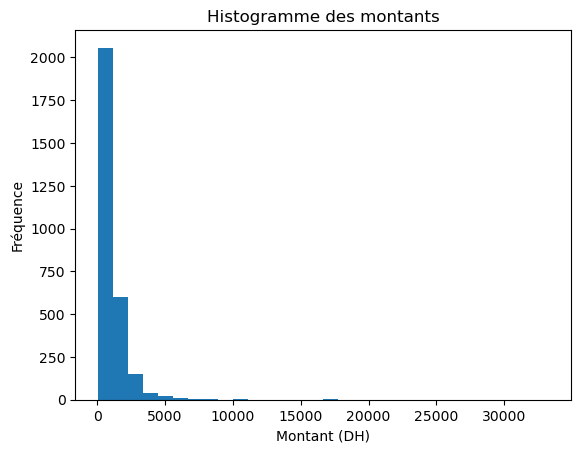

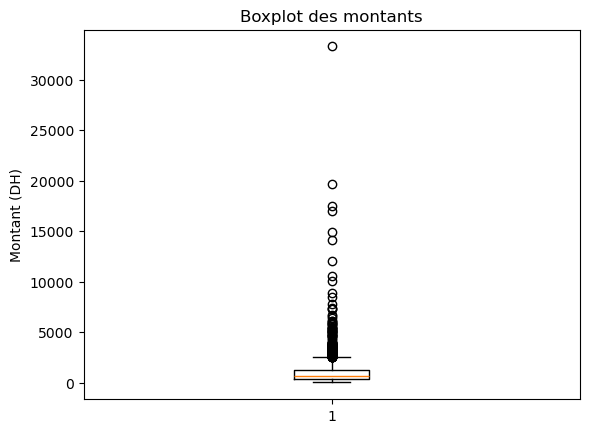

In [156]:
# Histogramme
plt.hist(df["montant_dh"].dropna(), bins=30)
plt.title("Histogramme des montants")
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.show()

# Boxplot
plt.boxplot(df["montant_dh"].dropna())
plt.title("Boxplot des montants")
plt.ylabel("Montant (DH)")
plt.show()

### 4 .

In [157]:
print(df["fraude"].value_counts())
print(df["fraude"].value_counts(normalize=True) * 100)

fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


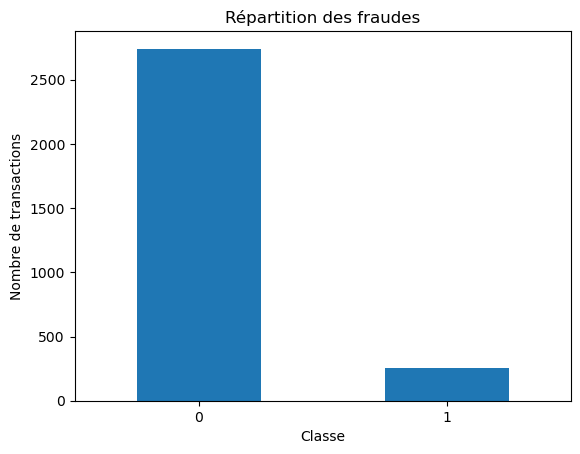

In [158]:
df["fraude"].value_counts().plot(kind="bar")

plt.title("Répartition des fraudes")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=0)
plt.show()

### 6 :

In [159]:
print(df.columns)

Index(['id_operation', 'id_client', 'montant_dh', 'anciennete_mois',
       'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international',
       'resultat_enquete', 'fraude'],
      dtype='object')


### Partie 2 — Préparer les données sans fuite

### 7 :

In [160]:
# Créer y : variable cible
y = df["fraude"]

# Créer X : variables explicatives
X = df.drop(["id_operation", "id_client", "resultat_enquete", "fraude"], axis=1)

# Afficher les résultats
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nColonnes de X :")
print(X.columns)

print("\nRépartition de y :")
print(y.value_counts())

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)

Colonnes de X :
Index(['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal',
       'appareil', 'region', 'international'],
      dtype='object')

Répartition de y :
fraude
0    2742
1     258
Name: count, dtype: int64


### 8 : 

In [161]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [162]:
print("Groupe de référence :")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nGroupe de vérification :")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Groupe de référence :
fraude
0    2194
1     206
Name: count, dtype: int64
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Groupe de vérification :
fraude
0    548
1     52
Name: count, dtype: int64
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


### 9 :

In [163]:
print(X.dtypes)

montant_dh         float64
anciennete_mois    float64
nb_ops_24h         float64
heure                int64
canal               object
appareil            object
region              object
international       object
dtype: object


### 10 : 

In [164]:
num_cols = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]

In [165]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [166]:
X_train_num = num_pipeline.fit_transform(X_train[num_cols])

In [167]:
X_test_num = num_pipeline.transform(X_test[num_cols])

In [168]:
print("Dimensions X_train_num :", X_train_num.shape)
print("Dimensions X_test_num :", X_test_num.shape)

print("Valeurs manquantes train :", np.isnan(X_train_num).sum())
print("Valeurs manquantes test :", np.isnan(X_test_num).sum())

Dimensions X_train_num : (2400, 4)
Dimensions X_test_num : (600, 4)
Valeurs manquantes train : 0
Valeurs manquantes test : 0


### 11 : 

In [169]:
cat_cols = ["canal", "appareil", "region", "international"]

In [170]:
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [171]:
X_train_cat = cat_pipeline.fit_transform(X_train[cat_cols])
X_test_cat = cat_pipeline.transform(X_test[cat_cols])

In [172]:
print("Dimensions X_train_cat :", X_train_cat.shape)
print("Dimensions X_test_cat :", X_test_cat.shape)

print("\nNoms des nouvelles variables :")
print(cat_pipeline.named_steps["encoder"].get_feature_names_out(cat_cols))

Dimensions X_train_cat : (2400, 14)
Dimensions X_test_cat : (600, 14)

Noms des nouvelles variables :
['canal_agence' 'canal_application' 'canal_site_web' 'canal_telephone'
 'appareil_mobile' 'appareil_ordinateur' 'appareil_terminal'
 'region_Autre' 'region_Casablanca-Settat' 'region_Draa-Tafilalet'
 'region_Marrakech-Safi' 'region_Souss-Massa' 'international_non'
 'international_oui']


### 12 :

In [173]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [174]:
X_train_final = preprocessor.fit_transform(X_train)

In [175]:
X_test_final = preprocessor.transform(X_test)

In [176]:
print("Dimensions X_train_final :", X_train_final.shape)
print("Dimensions X_test_final :", X_test_final.shape)

Dimensions X_train_final : (2400, 18)
Dimensions X_test_final : (600, 18)


### 13 :

In [177]:
robust_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

In [178]:
X_train_robust = robust_pipeline.fit_transform(X_train[num_cols])

In [179]:
X_test_robust = robust_pipeline.transform(X_test[num_cols])

In [180]:

comparaison = pd.DataFrame({
    "Montant_original": X_train["montant_dh"],
    "StandardScaler": X_train_num[:, 0],
    "RobustScaler": X_train_robust[:, 0]
})

print(comparaison.head(10))

      Montant_original  StandardScaler  RobustScaler
384             419.53       -0.452796     -0.356740
2064            533.01       -0.367320     -0.217748
625             477.87       -0.408852     -0.285284
267            2518.08        1.127884      2.213595
2306            394.74       -0.471468     -0.387103
18              658.53       -0.272775     -0.064009
3014            250.89       -0.579819     -0.563292
2953            421.09       -0.451621     -0.354829
77              402.85       -0.465359     -0.377169
1754            479.71       -0.407467     -0.283030


### 15 

In [181]:
Q1 = X_train["montant_dh"].quantile(0.25)
Q3 = X_train["montant_dh"].quantile(0.75)

print("Q1 :", Q1)
print("Q3 :", Q3)

Q1 : 393.095
Q3 : 1249.8775


In [182]:
IQR = Q3 - Q1

print("IQR :", IQR)

IQR : 856.7825


In [183]:
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)

Borne inférieure : -892.0787499999999
Borne supérieure : 2535.05125


In [184]:
outliers = X_train[
    (X_train["montant_dh"] < borne_inf) |
    (X_train["montant_dh"] > borne_sup)
]

print("Nombre de lignes concernées :", len(outliers))

Nombre de lignes concernées : 146


In [185]:
print(outliers[["montant_dh"]].head(10))

      montant_dh
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99
2088     2645.74
1105     6733.98
1074     2535.89
396      3002.07
329      5021.72


### 16 : 

In [186]:
montants = X_train["montant_dh"].copy()

In [187]:
montants_limites = montants.clip(
    lower=borne_inf,
    upper=borne_sup
)

### 17 :

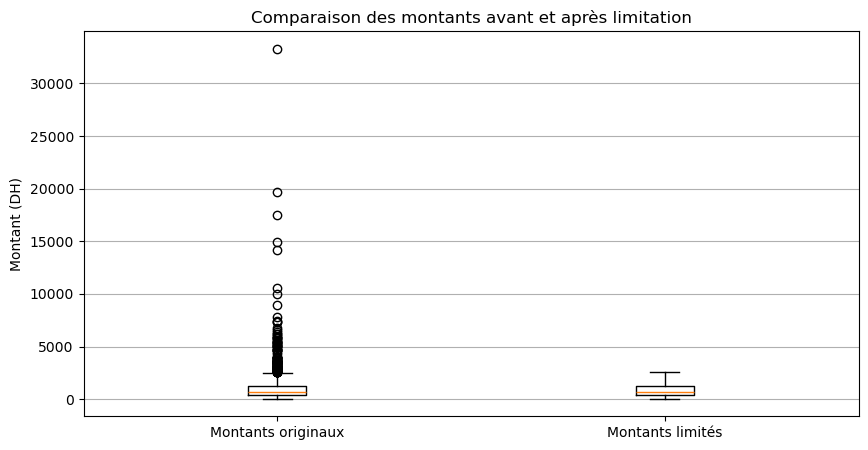

In [188]:

# Montants originaux
montants = X_train["montant_dh"].copy()

# Montants limités
montants_limites = montants.clip(
    lower=borne_inf,
    upper=borne_sup
)

# Comparaison des boxplots
plt.figure(figsize=(10, 5))

plt.boxplot(
    [montants.dropna(), montants_limites.dropna()],
    tick_labels=["Montants originaux", "Montants limités"]
)

plt.title("Comparaison des montants avant et après limitation")
plt.ylabel("Montant (DH)")
plt.grid(axis="y")

plt.show()

### 18 : 

In [189]:
scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

In [190]:
# MinMaxScaler
montant_train_minmax = scaler_minmax.fit_transform(
    X_train[["montant_dh"]]
)

montant_test_minmax = scaler_minmax.transform(
    X_test[["montant_dh"]]
)

# StandardScaler
montant_train_standard = scaler_standard.fit_transform(
    X_train[["montant_dh"]]
)

montant_test_standard = scaler_standard.transform(
    X_test[["montant_dh"]]
)

# RobustScaler
montant_train_robust = scaler_robust.fit_transform(
    X_train[["montant_dh"]]
)

montant_test_robust = scaler_robust.transform(
    X_test[["montant_dh"]]
)

In [191]:
print("MinMaxScaler :")
print(montant_test_minmax[:5])

print("\nStandardScaler :")
print(montant_test_standard[:5])

print("\nRobustScaler :")
print(montant_test_robust[:5])

MinMaxScaler :
[[0.02283333]
 [0.03334204]
 [0.00669849]
 [0.00936657]
 [0.01248164]]

StandardScaler :
[[-0.17536899]
 [ 0.08317633]
 [-0.57233403]
 [-0.50669123]
 [-0.43005122]]

RobustScaler :
[[ 0.0988699 ]
 [ 0.50662799]
 [-0.52719331]
 [-0.42366645]
 [-0.30279563]]


### 19 :

In [192]:
# Valeurs non manquantes du groupe de vérification
montants_test = X_test["montant_dh"].dropna()

# Trois montants habituels proches de Q1, médiane et Q3
indices = []

for valeur in [Q1, X_train["montant_dh"].median(), Q3]:
    idx = (montants_test - valeur).abs().idxmin()
    if idx not in indices:
        indices.append(idx)

# Montant très élevé
idx_max = montants_test.idxmax()

if idx_max not in indices:
    indices.append(idx_max)

# Tableau des montants sélectionnés
echantillon = X_test.loc[indices, ["montant_dh"]].copy()

print(echantillon)

      montant_dh
1427      391.70
1180      710.16
2210     1248.93
1557    16962.99


In [193]:
tableau = pd.DataFrame({
    "Montant initial": echantillon["montant_dh"],
    "MinMaxScaler": scaler_minmax.transform(echantillon).ravel(),
    "StandardScaler": scaler_standard.transform(echantillon).ravel(),
    "RobustScaler": scaler_robust.transform(echantillon).ravel()
})

print(tableau.round(3))

      Montant initial  MinMaxScaler  StandardScaler  RobustScaler
1427           391.70         0.011          -0.474        -0.372
1180           710.16         0.020          -0.239        -0.001
2210          1248.93         0.036           0.160         0.628
1557         16962.99         0.509          11.789        18.969


### 20 :

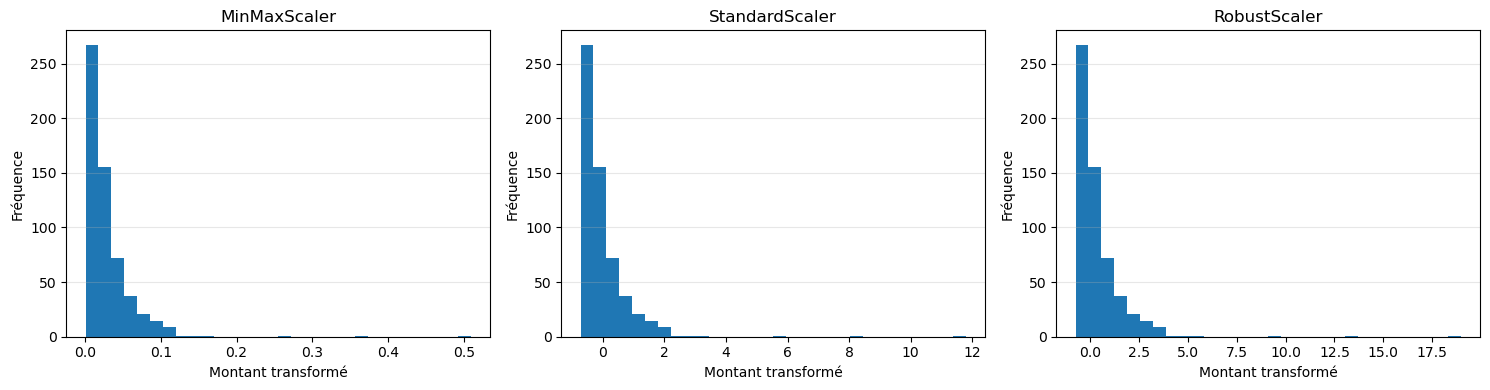

In [194]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(montant_test_minmax.flatten(), bins=30)
axes[0].set_title("MinMaxScaler")

axes[1].hist(montant_test_standard.flatten(), bins=30)
axes[1].set_title("StandardScaler")

axes[2].hist(montant_test_robust.flatten(), bins=30)
axes[2].set_title("RobustScaler")

for ax in axes:
    ax.set_xlabel("Montant transformé")
    ax.set_ylabel("Fréquence")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 21 : 

In [195]:
# Maximum du groupe de référence
max_train = X_train["montant_dh"].max()

# Nouvelle transaction supérieure au maximum
nouveau_montant = max_train + 1000

# Transformation avec MinMaxScaler
resultat = scaler_minmax.transform(
    pd.DataFrame({"montant_dh": [nouveau_montant]})
)

print("Nouveau montant :", nouveau_montant)
print("Valeur transformée :", resultat[0, 0])

Nouveau montant : 34281.23
Valeur transformée : 1.030079874097679


### 22 : 

In [196]:
# Avant rééquilibrage
print("Avant RandomOverSampler :")
print(y_train.value_counts())

# Application
ros = RandomOverSampler(random_state=42)

X_train_over, y_train_over = ros.fit_resample(
    X_train, y_train
)

# Après rééquilibrage
print("\nAprès RandomOverSampler :")
print(y_train_over.value_counts())

print("Nombre total :", len(y_train_over))

Avant RandomOverSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64
Nombre total : 4388


### 23 :  

In [197]:

print("Avant RandomOverSampler :")
print(y_train.value_counts())

# Application
ros = RandomOverSampler(random_state=42)

X_train_over, y_train_over = ros.fit_resample(
    X_train, y_train
)

# Après rééquilibrage
print("\nAprès RandomOverSampler :")
print(y_train_over.value_counts())

print("Nombre total :", len(y_train_over))

Avant RandomOverSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64
Nombre total : 4388


### 24 :

In [198]:
from imblearn.under_sampling import RandomUnderSampler

# Application sur les données originales
rus = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = rus.fit_resample(
    X_train, y_train
)

print("Avant RandomUnderSampler :")
print(y_train.value_counts())

print("\nAprès RandomUnderSampler :")
print(y_train_under.value_counts())

print("\nNombre de lignes avant :", len(y_train))
print("Nombre de lignes après :", len(y_train_under))

print("Nombre de lignes supprimées :",
      len(y_train) - len(y_train_under))

Avant RandomUnderSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomUnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes après : 412
Nombre de lignes supprimées : 1988


In [199]:
A = [2, 3]
B = [6, 7]

lambda_ = 0.25

S = [
    A[i] + lambda_ * (B[i] - A[i])
    for i in range(2)
]

print("Observation A :", A)
print("Observation B :", B)
print("Observation synthétique :", S)

Observation A : [2, 3]
Observation B : [6, 7]
Observation synthétique : [3.0, 4.0]


### 26 

### 27 

In [200]:
print("Groupe de vérification :")
print(y_test.value_counts().sort_index())

print("Nombre total :", len(y_test))

Groupe de vérification :
fraude
0    548
1     52
Name: count, dtype: int64
Nombre total : 600


### 28 

In [201]:
numeriques = [
    'montant_dh',
    'anciennete_mois',
    'nb_ops_24h',
    'heure'
]

categories = [
    'canal',
    'appareil',
    'region',
    'international'
]

# Vérifier les colonnes
print("Variables numériques :", numeriques)
print("Variables catégorielles :", categories)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


### 29 

In [202]:
# Ajustement sur le groupe de référence uniquement
X_train_final = preprocessor.fit_transform(X_train)

# Application au groupe de vérification
X_test_final = preprocessor.transform(X_test)

# Vérification des dimensions
print("Dimensions train :", X_train_final.shape)
print("Dimensions test :", X_test_final.shape)

# Vérification des valeurs manquantes
import numpy as np

print("Valeurs manquantes train :",
      np.isnan(X_train_final).sum())

print("Valeurs manquantes test :",
      np.isnan(X_test_final).sum())

Dimensions train : (2400, 18)
Dimensions test : (600, 18)
Valeurs manquantes train : 0
Valeurs manquantes test : 0


In [203]:
from scipy.sparse import issparse

def compter_nan(X):
    if issparse(X):
        return np.isnan(X.data).sum()
    return np.isnan(X).sum()

print("NaN train :", compter_nan(X_train_final))
print("NaN test :", compter_nan(X_test_final))

NaN train : 0
NaN test : 0


### 30 : 

In [204]:
# Prendre une ligne du groupe de vérification
nouvelle_ligne = X_test.iloc[[0]].copy()

# Simuler une nouvelle catégorie inconnue
nouvelle_ligne['canal'] = 'Canal_Inconnu'

# Transformation
resultat = preprocessor.transform(nouvelle_ligne)

print("Transformation réussie !")
print("Dimensions :", resultat.shape)

Transformation réussie !
Dimensions : (1, 18)


### 31 : 

In [205]:
import joblib

joblib.dump(preprocessor, 'preprocessor_fraude.pkl')

print("Transformateur enregistré.")

Transformateur enregistré.


In [206]:
preprocessor_charge = joblib.load('preprocessor_fraude.pkl')

print("Transformateur rechargé.")

Transformateur rechargé.


In [207]:
# Petit échantillon
echantillon = X_train.iloc[:5]

# Transformation avec le transformateur original
resultat1 = preprocessor.transform(echantillon)

# Transformation avec le transformateur rechargé
resultat2 = preprocessor_charge.transform(echantillon)

# Comparaison
if issparse(resultat1):
    resultat1 = resultat1.toarray()

if issparse(resultat2):
    resultat2 = resultat2.toarray()

print("Résultats identiques :",
      np.allclose(resultat1, resultat2))

Résultats identiques : True


### 32 :

In [208]:
# Nombre de doublons supprimés
print("Doublons supprimés : 45")

# Valeurs manquantes dans les données transformées
print("NaN train :", compter_nan(X_train_final))
print("NaN test :", compter_nan(X_test_final))

# Dimensions après transformation
print("Train :", X_train_final.shape)
print("Test :", X_test_final.shape)

# Répartition avant rééquilibrage
print("\nAvant rééquilibrage :")
print(y_train.value_counts())

# Répartition après rééquilibrage
print("\nRandomOverSampler :")
print(y_train_over.value_counts())

print("\nRandomUnderSampler :")
print(y_train_under.value_counts())

Doublons supprimés : 45
NaN train : 0
NaN test : 0
Train : (2400, 18)
Test : (600, 18)

Avant rééquilibrage :
fraude
0    2194
1     206
Name: count, dtype: int64

RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64

RandomUnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64


In [209]:
import numpy as np
import pandas as pd

# Copier la variable
montants = X_train['montant_dh'].copy()

# Ajouter une valeur manquante
montants_test = montants.copy()
montants_test.iloc[0] = np.nan

# Calculer la moyenne et la médiane
moyenne = montants_test.mean()
mediane = montants_test.median()

print("Moyenne :", moyenne)
print("Médiane :", mediane)

# Ajouter un montant très élevé
montants_extremes = montants_test.copy()
montants_extremes.iloc[1] = 1000000

print("\nAprès ajout d'un montant extrême :")
print("Nouvelle moyenne :", montants_extremes.mean())
print("Nouvelle médiane :", montants_extremes.median())

Moyenne : 1032.7330030289916
Médiane : 711.29

Après ajout d'un montant extrême :
Nouvelle moyenne : 1465.2154738208565
Nouvelle médiane : 711.45


In [212]:
from sklearn.impute import SimpleImputer

X_train_mix = X_train.copy()

# Variables numériques
imp_num = SimpleImputer(strategy='median')
X_train_mix[numeriques] = imp_num.fit_transform(
    X_train_mix[numeriques]
)

# Variables catégorielles
imp_cat = SimpleImputer(strategy='most_frequent')
X_train_mix[categories] = imp_cat.fit_transform(
    X_train_mix[categories]
)

In [213]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categories,
    random_state=42
)

X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train_mix, y_train
)

print("Avant :")
print(y_train.value_counts())

print("\nAprès SMOTENC :")
print(y_train_smote.value_counts())

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64

Après SMOTENC :
fraude
0    2194
1    2194
Name: count, dtype: int64


In [214]:
for col in categories:
    print("\nVariable :", col)
    print(X_train_smote[col].value_counts())


Variable : canal
canal
application    2243
site_web        964
agence          671
telephone       510
Name: count, dtype: int64

Variable : appareil
appareil
mobile        3074
ordinateur     989
terminal       325
Name: count, dtype: int64

Variable : region
region
Draa-Tafilalet       1139
Casablanca-Settat    1125
Marrakech-Safi        854
Autre                 720
Souss-Massa           550
Name: count, dtype: int64

Variable : international
international
non    3929
oui     459
Name: count, dtype: int64
